# Data Structures & Algorithms: Searching and Sorting

> **Who is this for:** learners who can write loops and functions and know Big-O, and who want to master the two most studied problem families in computer science, for exams, interviews and everyday data work.
>
> **What you will learn:**
> - Linear search; binary search (iterative and recursive), lower/upper bound, rotated arrays, binary search *on the answer*, Python's `bisect`
> - Ten sorting algorithms implemented from scratch: bubble, selection, insertion, merge, quick (Lomuto, Hoare, random pivot), heap, counting, radix and bucket sort
> - Step-by-step pictures of how sorts move data; stability and in-place properties
> - A complexity comparison table and a benchmark on random, sorted and reversed inputs
> - Why comparison sorting needs Ω(n log n) comparisons, and why Python's Timsort is so fast on real data
> - Quickselect (k-th smallest) and merging intervals
>
> **Prerequisites:** [01 · Complexity and recursion](01_complexity_analysis_and_recursion.ipynb) (Big-O, recursion, Master theorem), [02 · Arrays and techniques](02_arrays_strings_and_techniques.ipynb) (two pointers, Dutch national flag).
>
> **Time needed:** about 3 hours.
>
> **Runs on:** CPU, no API key, no internet (the whole notebook runs in about a minute).
>
> **Optional track:** this notebook is part of the university-level fundamentals track; recommended for BS/MS AI students and interview prep. It follows the "Searching" and "Sorting" sections of the GeeksforGeeks DSA tutorial and CLRS chapters 2, 6, 7, 8 and 9.

## Explained simply

**Searching** means finding an item; **sorting** means putting items in order. They go together: once data is sorted, you can find things incredibly fast by repeatedly cutting the search area in half (**binary search**). There are many ways to sort. Simple ones compare neighbours over and over and are slow for big lists; clever ones split the list into halves, sort the halves and combine them. Some special sorts don't compare items at all; they simply count them. Python's built-in `sorted()` is a very well-engineered mix of these ideas, and understanding why it is fast helps you write faster code.

**Everyday examples**
- **Binary search**: the guessing game "I'm thinking of a number from 1 to 100": guess 50, hear "higher", guess 75, and so on. You never need more than 7 guesses.
- **Insertion sort**: how most people sort a hand of playing cards, sliding each new card left into its place.
- **Counting sort**: a teacher sorting 200 test papers by grade (A–F) by dropping each into one of six piles, then stacking the piles.

**Tiny example.** Find 23 in the sorted list `[2, 5, 8, 12, 16, 23, 38]`. Look at the middle (12): 23 is bigger, so throw away the left half. In `[16, 23, 38]` the middle is 23: found in **2 looks** instead of 6. With a million sorted items, binary search needs at most 20 looks.

**In one line**

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Binary search | halve the search area with every look | finding a word in a dictionary; picking the next token from cumulative probabilities |
| Merge / quick sort | split the list, sort the parts, combine | `sorted()`, database `ORDER BY`, ranking search results |
| Quickselect / top-k | find the k best without sorting everything | returning the 5 most similar documents in RAG |

## Table of contents
1. Linear search
2. Binary search: iterative, recursive, lower/upper bound, `bisect`
3. Binary search variants: rotated arrays and binary search on the answer
4. Elementary sorts: bubble, selection, insertion
5. Divide and conquer sorts: merge sort and quick sort (Lomuto, Hoare, random pivot)
6. Heap sort
7. Non-comparison sorts: counting, radix, bucket
8. Watching sorts work (step snapshots)
9. Stability and in-place sorting
10. Comparison table and benchmark
11. The Ω(n log n) lower bound for comparison sorts
12. Timsort: Python's `sorted`
13. Quickselect and merging intervals
14. How this connects to modern AI
15. Recap, practice problems, further reading

In [1]:
# Standard setup used throughout this notebook
import random, math, time, timeit, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)          # reproducible random numbers (Python)
np.random.seed(42)       # reproducible random numbers (NumPy)

# One consistent, colour-blind-friendly palette for every chart in this module
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.titleweight": "bold", "figure.dpi": 100,
})
pd.set_option("display.width", 140)
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__)

import bisect, heapq
from collections import Counter

Python 3.12.3 | numpy 2.4.6 | pandas 2.3.3


---
## 1. Linear search

> 💡 **In plain English:** check the items one by one until you find what you want.

**Intuition.** Looking for your keys by checking every pocket one by one.

**Linear (sequential) search** checks each element in turn until it finds the target or runs out of elements. It works on **any** list, sorted or not.

| Case | Comparisons | Time |
|---|---|---|
| best (first element) | 1 | O(1) |
| worst (last or absent) | n | O(n) |
| average (present, uniform position) | (n + 1)/2 | O(n) |

Space O(1). Use it for small or unsorted data, or when you search only once (sorting first costs O(n log n), more than a single O(n) scan).

In [2]:
def linear_search(a, target):
    """Return the first index of target in a, or -1."""
    for i, x in enumerate(a):
        if x == target:
            return i
    return -1

for _ in range(2000):
    a = [random.randint(0, 9) for _ in range(random.randint(0, 10))]
    t = random.randint(0, 10)
    assert linear_search(a, t) == (a.index(t) if t in a else -1)   # compare with list.index
print("linear_search agrees with list.index on 2000 random tests")

linear_search agrees with list.index on 2000 random tests


---
## 2. Binary search

> 💡 **In plain English:** on sorted data, look in the middle and throw away the half that can't contain the target.

**Intuition.** Finding a word in a paper dictionary: open in the middle, see whether your word comes before or after, and throw away the wrong half. Each look halves the remaining pages.

**Binary search** finds a target in a **sorted** array by comparing it with the middle element and discarding half of the remaining range each step. After k steps, n/2ᵏ elements remain, so it needs at most ⌊log₂ n⌋ + 1 comparisons: **O(log n)**. A million elements need at most 20 comparisons; a billion, 30.

Hand trace, searching for 23 in `[2, 5, 8, 12, 16, 23, 38, 56, 72, 91]`:

| step | lo | hi | mid | a[mid] | decision |
|---|---|---|---|---|---|
| 1 | 0 | 9 | 4 | 16 | 16 < 23 → lo = 5 |
| 2 | 5 | 9 | 7 | 56 | 56 > 23 → hi = 6 |
| 3 | 5 | 6 | 5 | 23 | **found at index 5** |

The **loop invariant** (what is always true): *if the target is in the array, it is inside a[lo..hi]*. Each step keeps the invariant and shrinks the range, so the algorithm is correct and terminates.

**Lower and upper bound.** With duplicates, "find any occurrence" is not enough.
- **lower_bound(x)**: first index i with a[i] **≥** x (where x would be inserted to stay sorted, before equal elements). Python: `bisect.bisect_left`.
- **upper_bound(x)**: first index i with a[i] **>** x. Python: `bisect.bisect_right`.
- The number of occurrences of x is **upper_bound − lower_bound**; the first occurrence is at lower_bound if a[lower_bound] == x.

In [3]:
def binary_search(a, target, trace=None):
    """Iterative binary search on a sorted list. Returns an index of target or -1."""
    lo, hi = 0, len(a) - 1                 # search the closed range a[lo..hi]
    while lo <= hi:
        mid = (lo + hi) // 2               # (in C/Java write lo + (hi - lo) // 2 to avoid overflow)
        if trace is not None: trace.append({"lo": lo, "hi": hi, "mid": mid, "a[mid]": a[mid]})
        if a[mid] == target:
            return mid
        if a[mid] < target:
            lo = mid + 1                   # target can only be to the right
        else:
            hi = mid - 1                   # target can only be to the left
    return -1

def binary_search_rec(a, target, lo=0, hi=None):
    """Recursive version: T(n) = T(n/2) + O(1) = O(log n) time, O(log n) stack space."""
    if hi is None:
        hi = len(a) - 1
    if lo > hi:                            # base case: empty range
        return -1
    mid = (lo + hi) // 2
    if a[mid] == target:
        return mid
    if a[mid] < target:
        return binary_search_rec(a, target, mid + 1, hi)
    return binary_search_rec(a, target, lo, mid - 1)

def lower_bound(a, x):
    """First index i with a[i] >= x (len(a) if none). Half-open range [lo, hi)."""
    lo, hi = 0, len(a)
    while lo < hi:
        mid = (lo + hi) // 2
        if a[mid] < x:
            lo = mid + 1
        else:
            hi = mid                       # a[mid] >= x: mid could be the answer, keep it
    return lo

def upper_bound(a, x):
    """First index i with a[i] > x (len(a) if none)."""
    lo, hi = 0, len(a)
    while lo < hi:
        mid = (lo + hi) // 2
        if a[mid] <= x:
            lo = mid + 1
        else:
            hi = mid
    return lo

a = [2, 5, 8, 12, 16, 23, 38, 56, 72, 91]
tr = []
print("binary_search(a, 23) =", binary_search(a, 23, tr))
display(pd.DataFrame(tr))

b = [1, 2, 2, 2, 3, 5, 5, 8]
print(f"b = {b}: lower_bound(2) = {lower_bound(b, 2)}, upper_bound(2) = {upper_bound(b, 2)}, "
      f"count(2) = {upper_bound(b, 2) - lower_bound(b, 2)}, lower_bound(4) = {lower_bound(b, 4)}")

for _ in range(5000):                                         # random tests against bisect and list.index
    a = sorted(random.randint(0, 20) for _ in range(random.randint(0, 15)))
    x = random.randint(-1, 21)
    assert lower_bound(a, x) == bisect.bisect_left(a, x)
    assert upper_bound(a, x) == bisect.bisect_right(a, x)
    for f in (binary_search, binary_search_rec):
        i = f(a, x)
        assert (i == -1) == (x not in a) and (i == -1 or a[i] == x)
print("5000 random tests: binary searches find x iff present; lower/upper bound == bisect_left/right")

binary_search(a, 23) = 5


,lo,hi,mid,a[mid]
0,0,9,4,16
1,5,9,7,56
2,5,6,5,23


b = [1, 2, 2, 2, 3, 5, 5, 8]: lower_bound(2) = 1, upper_bound(2) = 4, count(2) = 3, lower_bound(4) = 5


5000 random tests: binary searches find x iff present; lower/upper bound == bisect_left/right


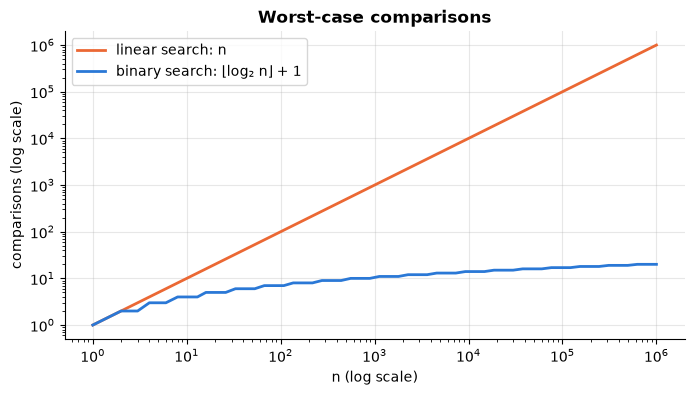

n =        10: worst observed = 4 steps, bound ⌊log₂ n⌋ + 1 = 4
n =     1,000: worst observed = 10 steps, bound ⌊log₂ n⌋ + 1 = 10
n = 1,000,000: worst observed = 20 steps, bound ⌊log₂ n⌋ + 1 = 20


In [4]:
# Comparisons in the worst case: linear vs binary search
ns = np.unique(np.logspace(0, 6, 60).astype(int))
binary_worst = np.floor(np.log2(ns)) + 1
fig, ax = plt.subplots(figsize=(8, 4))
ax.loglog(ns, ns, label="linear search: n", color=PALETTE[1])
ax.loglog(ns, binary_worst, label="binary search: ⌊log₂ n⌋ + 1", color=PALETTE[0])
ax.set(title="Worst-case comparisons", xlabel="n (log scale)", ylabel="comparisons (log scale)")
ax.legend(); plt.show()

# Check the worst case empirically: search for a missing value, counting loop iterations
def bs_count(a, target):
    lo, hi, steps = 0, len(a) - 1, 0
    while lo <= hi:
        steps += 1
        mid = (lo + hi) // 2
        if a[mid] == target: return steps
        if a[mid] < target: lo = mid + 1
        else: hi = mid - 1
    return steps
for n in [10, 1000, 10**6]:
    arr = list(range(0, 2 * n, 2))                    # even numbers; odd targets are missing
    worst = max(bs_count(arr, t) for t in [-1, 2 * n + 1] + [random.randrange(1, 2 * n, 2) for _ in range(200)])
    print(f"n = {n:>9,}: worst observed = {worst} steps, bound ⌊log₂ n⌋ + 1 = {math.floor(math.log2(n)) + 1}")
    assert worst <= math.floor(math.log2(n)) + 1

**What just happened?** The trace table matches our hand trace (found 23 at index 5 in 3 steps). On `[1, 2, 2, 2, 3, 5, 5, 8]` the three 2s span indices 1–3, so lower_bound(2) = 1, upper_bound(2) = 4 and the count is 3; lower_bound(4) = 5 is where 4 would be inserted. All variants agree with `bisect` on 5000 random tests. The plot and measurements show binary search never needs more than ⌊log₂ n⌋ + 1 steps (20 for a million elements).

> ⚠️ **Common mistake:** mixing up conventions. With a closed range `[lo, hi]` use `while lo <= hi` and `hi = mid - 1`; with a half-open range `[lo, hi)` use `while lo < hi` and `hi = mid`. Mixing them causes infinite loops or off-by-one errors. Another classic infinite loop: `lo = mid` together with `mid = (lo + hi) // 2` when hi = lo + 1.

### Python's `bisect` module
`bisect_left`, `bisect_right` and `insort` (insert keeping the list sorted) are implemented in C. Since Python 3.10 they accept a `key=` argument.

In [5]:
# Classic bisect use: map a score to a grade with sorted breakpoints
breakpoints = [60, 70, 80, 90]
grades = "FDCBA"
def grade(score):
    return grades[bisect.bisect_right(breakpoints, score)]   # how many breakpoints are <= score
print([(s, grade(s)) for s in [33, 60, 77, 89, 90, 100]])

# insort keeps a list sorted as we add items (O(log n) search + O(n) shifting)
scores = []
for s in [50, 20, 80, 20, 65]:
    bisect.insort(scores, s)
print("insort result:", scores)

# key= (Python 3.10+): search records sorted by a field
people = sorted([("ana", 31), ("bo", 25), ("cy", 40)], key=lambda p: p[1])
print("first person aged >= 30:", people[bisect.bisect_left(people, 30, key=lambda p: p[1])])

[(33, 'F'), (60, 'D'), (77, 'C'), (89, 'B'), (90, 'A'), (100, 'A')]
insort result: [20, 20, 50, 65, 80]
first person aged >= 30: ('ana', 31)


---
## 3. Binary search variants

> 💡 **In plain English:** binary search also works on rotated lists and on yes/no questions such as "is capacity X enough?".

### Search in a rotated sorted array
A sorted array rotated at an unknown pivot, e.g. `[15, 18, 22, 3, 6, 9, 12]` (distinct values). At any `mid`, **at least one half is sorted**. Check whether the target lies inside the sorted half's range; if yes, search there, otherwise search the other half. Still O(log n).

### Binary search on the answer
Many optimisation problems have a **monotone yes/no predicate**: if capacity C works, every bigger capacity also works. Then we can binary-search the *smallest value for which the predicate is true*, even though we are not searching in an array at all.

```
capacity:   10  11  12  13  14  15  16 ...
feasible?    F   F   F   F   F   T   T  ...   ← monotone: find the first T
```

- **Integer square root**: largest r with r² ≤ n (predicate "r² > n" is monotone).
- **Minimum ship capacity**: packages with weights w must be shipped *in order* within D days; what is the smallest ship capacity? Answer lies in [max(w), sum(w)]; checking a capacity is a greedy O(n) simulation, so the total is **O(n log(sum w))**.

In [6]:
def search_rotated(a, target):
    """Index of target in a rotated sorted array of DISTINCT values, or -1. O(log n)."""
    lo, hi = 0, len(a) - 1
    while lo <= hi:
        mid = (lo + hi) // 2
        if a[mid] == target:
            return mid
        if a[lo] <= a[mid]:                       # left half a[lo..mid] is sorted
            if a[lo] <= target < a[mid]:
                hi = mid - 1                      # target is inside the sorted left half
            else:
                lo = mid + 1
        else:                                     # right half a[mid..hi] is sorted
            if a[mid] < target <= a[hi]:
                lo = mid + 1
            else:
                hi = mid - 1
    return -1

def isqrt(n):
    """Largest r with r*r <= n, by binary search on the answer. O(log n)."""
    lo, hi = 0, n + 1                             # answer in [lo, hi)
    while hi - lo > 1:
        mid = (lo + hi) // 2
        if mid * mid <= n:
            lo = mid                              # mid is feasible: answer >= mid
        else:
            hi = mid
    return lo

def days_needed(weights, cap):
    """Greedy: load packages in order until the next one doesn't fit."""
    days, load = 1, 0
    for w in weights:
        if load + w > cap:
            days, load = days + 1, 0
        load += w
    return days

def ship_capacity(weights, D):
    lo, hi = max(weights), sum(weights)           # smallest possible and always-feasible capacities
    while lo < hi:
        mid = (lo + hi) // 2
        if days_needed(weights, mid) <= D:        # feasible: try smaller
            hi = mid
        else:
            lo = mid + 1
    return lo

def ship_capacity_brute(weights, D):
    cap = max(weights)
    while days_needed(weights, cap) > D:          # try every capacity upwards
        cap += 1
    return cap

print("search_rotated([15,18,22,3,6,9,12], 6) =", search_rotated([15, 18, 22, 3, 6, 9, 12], 6))
print("isqrt(10**20 + 12345) =", isqrt(10**20 + 12345))
w = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
print("ship_capacity(1..10, D=5) =", ship_capacity(w, 5))

for _ in range(3000):
    base = sorted(random.sample(range(100), random.randint(1, 12)))
    k = random.randrange(len(base)); a = base[k:] + base[:k]          # rotate
    t = random.randint(-1, 100)
    assert search_rotated(a, t) == (a.index(t) if t in a else -1)
    n = random.randint(0, 10**12)
    assert isqrt(n) == math.isqrt(n)
    ws = [random.randint(1, 10) for _ in range(random.randint(1, 10))]
    D = random.randint(1, len(ws))
    assert ship_capacity(ws, D) == ship_capacity_brute(ws, D)
print("3000 random tests: rotated search == list.index, isqrt == math.isqrt, ship_capacity == brute force")

search_rotated([15,18,22,3,6,9,12], 6) = 4
isqrt(10**20 + 12345) = 10000000000
ship_capacity(1..10, D=5) = 15


3000 random tests: rotated search == list.index, isqrt == math.isqrt, ship_capacity == brute force


**What just happened?** 6 is found at index 4 of the rotated array; `isqrt(10²⁰ + 12345)` is exactly 10¹⁰; and to ship weights 1…10 within 5 days the minimum capacity is 15 (days: [1–5], [6, 7], [8], [9], [10]). All three agree with library or brute-force answers on 3000 random tests.

> 🎓 **Exam / interview tip:** when a question says "minimise the maximum…" or "find the smallest X such that…", ask yourself whether feasibility is monotone in X. If yes, binary search on the answer.

---
## 4. Elementary sorts: bubble, selection, insertion

> 💡 **In plain English:** three simple sorts that compare and swap neighbouring items: easy to write, slow on big lists.

**Sorting** rearranges items into non-decreasing order. Every implementation below returns a new sorted list, so we can test them all the same way.

**Bubble sort**: repeatedly walk the list swapping adjacent out-of-order pairs; after pass k, the k largest items have "bubbled" to the end. With an **early exit** (stop if a pass makes no swap) it is O(n) on sorted input.

**Selection sort**: find the minimum of the unsorted part and swap it to the front. Always n(n−1)/2 comparisons, but at most n − 1 swaps (useful when writes are expensive).

**Insertion sort**: like sorting playing cards in your hand: take the next card and slide it left into its place among the already-sorted cards. O(n) on nearly sorted data, which is why real libraries (Timsort) use it for short runs.

Hand example, insertion sort on `[5, 2, 4, 6, 1, 3]` (the sorted prefix is before the `|`):
```
5 | 2 4 6 1 3      insert 2 → 2 5 | 4 6 1 3
2 5 | 4 6 1 3      insert 4 → 2 4 5 | 6 1 3
2 4 5 | 6 1 3      insert 6 → 2 4 5 6 | 1 3   (no shifts)
2 4 5 6 | 1 3      insert 1 → 1 2 4 5 6 | 3   (4 shifts)
1 2 4 5 6 | 3      insert 3 → 1 2 3 4 5 6
```

In [7]:
def bubble_sort(a, snap=None):
    a = list(a)
    n = len(a)
    for i in range(n - 1):
        swapped = False
        for j in range(n - 1 - i):               # the last i items are already in place
            if a[j] > a[j + 1]:
                a[j], a[j + 1] = a[j + 1], a[j]
                swapped = True
        if snap is not None: snap.append(a[:])
        if not swapped:                          # early exit: already sorted
            break
    return a

def selection_sort(a, snap=None):
    a = list(a)
    n = len(a)
    for i in range(n - 1):
        m = i
        for j in range(i + 1, n):                # find the minimum of a[i..n-1]
            if a[j] < a[m]:
                m = j
        a[i], a[m] = a[m], a[i]                  # one swap per pass (this long-distance swap breaks stability)
        if snap is not None: snap.append(a[:])
    return a

def insertion_sort(a, snap=None):
    a = list(a)
    for i in range(1, len(a)):
        key = a[i]
        j = i - 1
        while j >= 0 and a[j] > key:             # shift larger elements one step right
            a[j + 1] = a[j]
            j -= 1
        a[j + 1] = key                           # drop the key into the gap
        if snap is not None: snap.append(a[:])
    return a

print(insertion_sort([5, 2, 4, 6, 1, 3]))

[1, 2, 3, 4, 5, 6]


---
## 5. Divide and conquer: merge sort and quick sort

> 💡 **In plain English:** split the list, sort the pieces recursively, then combine (merge sort) or split cleverly around a pivot (quick sort).

### Merge sort
**Divide** the list into two halves, **conquer** by sorting each half recursively, **combine** by merging two sorted lists (repeatedly take the smaller front element). Recurrence T(n) = 2T(n/2) + Θ(n) → **Θ(n log n) in every case** (Master theorem case 2, notebook 01). Needs Θ(n) extra memory for merging. Stable if ties are taken from the left half.

```
[38 27 43 3 9 82 10]
[38 27 43 3]        [9 82 10]          split
[38 27] [43 3]      [9 82] [10]
[27 38] [3 43]      [9 82] [10]        merge pairs
[3 27 38 43]        [9 10 82]
[3 9 10 27 38 43 82]                   final merge
```

### Quick sort
Pick a **pivot**, **partition** the array so smaller elements come before it and larger after it, then sort the two parts recursively. No merge step is needed and it sorts in place.
- **Lomuto partition**: pivot = last element; one index `i` marks the end of the "< pivot" zone while `j` scans. Simple, but more swaps.
- **Hoare partition**: two indices move towards each other from both ends and swap misplaced pairs. About 3× fewer swaps on average; the pivot does not necessarily end at its final position.
- **Pivot choice matters.** Best/average case: balanced splits → T(n) = 2T(n/2) + Θ(n) = **Θ(n log n)**. Worst case: the pivot is always the min or max (e.g. last-element pivot on already sorted input) → T(n) = T(n−1) + Θ(n) = **Θ(n²)**. A **random pivot** makes the *expected* time Θ(n log n) for every input.
- **Stack depth**: recursing into the *smaller* part and looping on the larger keeps the stack O(log n) even in the worst case. We use this trick below so that the bad cases are merely slow, not RecursionErrors.

In [8]:
def merge(left, right):
    """Merge two sorted lists. Ties are taken from LEFT, which makes merge sort stable."""
    out, i, j = [], 0, 0
    while i < len(left) and j < len(right):
        if right[j] < left[i]:                   # strictly smaller: take from right
            out.append(right[j]); j += 1
        else:                                    # left[i] <= right[j]: take from left (stability)
            out.append(left[i]); i += 1
    out.extend(left[i:]); out.extend(right[j:])  # one of these is empty
    return out

def merge_sort(a, snap=None):
    a = list(a)
    if len(a) <= 1:                              # base case
        return a
    mid = len(a) // 2
    return merge(merge_sort(a[:mid]), merge_sort(a[mid:]))

def quick_sort_lomuto(a, pivot="last", snap=None):
    a = list(a)
    def partition(lo, hi):
        if pivot == "random":                    # random pivot: move it to the end first
            r = random.randint(lo, hi)
            a[r], a[hi] = a[hi], a[r]
        p = a[hi]
        i = lo                                   # a[lo..i-1] < p
        for j in range(lo, hi):
            if a[j] < p:
                a[i], a[j] = a[j], a[i]
                i += 1
        a[i], a[hi] = a[hi], a[i]                # pivot goes to its final position i
        if snap is not None: snap.append(a[:])
        return i
    def sort(lo, hi):
        while lo < hi:
            p = partition(lo, hi)
            if p - lo < hi - p:                  # recurse on the smaller side, loop on the larger
                sort(lo, p - 1); lo = p + 1
            else:
                sort(p + 1, hi); hi = p - 1
    sort(0, len(a) - 1)
    return a

def quick_sort_random(a, snap=None):
    return quick_sort_lomuto(a, pivot="random", snap=snap)

def quick_sort_hoare(a, snap=None):
    a = list(a)
    def partition(lo, hi):
        p = a[(lo + hi) // 2]                    # middle element as pivot
        i, j = lo - 1, hi + 1
        while True:
            i += 1
            while a[i] < p: i += 1               # find an element on the left that belongs right
            j -= 1
            while a[j] > p: j -= 1               # find an element on the right that belongs left
            if i >= j:
                if snap is not None: snap.append(a[:])
                return j                         # a[lo..j] <= p <= a[j+1..hi]
            a[i], a[j] = a[j], a[i]
    def sort(lo, hi):
        while lo < hi:
            p = partition(lo, hi)
            if p - lo < hi - p:
                sort(lo, p); lo = p + 1
            else:
                sort(p + 1, hi); hi = p
    sort(0, len(a) - 1)
    return a

print(merge_sort([38, 27, 43, 3, 9, 82, 10]))
print(quick_sort_lomuto([38, 27, 43, 3, 9, 82, 10]), quick_sort_hoare([38, 27, 43, 3, 9, 82, 10]))

[3, 9, 10, 27, 38, 43, 82]
[3, 9, 10, 27, 38, 43, 82] [3, 9, 10, 27, 38, 43, 82]


---
## 6. Heap sort

> 💡 **In plain English:** keep the biggest item on top of a heap, move it to the end, and repeat.

A **binary max-heap** is an array viewed as a complete binary tree where every parent ≥ its children. For index i: children at 2i + 1 and 2i + 2, parent at (i − 1)//2. (Heaps get a full treatment in [06 · Trees, BSTs and heaps](06_trees_bst_and_heaps.ipynb); here we only need two operations.)

```
array: [9, 7, 8, 3, 5, 6]          tree:        9
                                              /   \
                                             7     8
                                            / \   /
                                           3   5 6
```
1. **Build a max-heap** in place by sifting down every internal node from the bottom up: **O(n)** total (most nodes are near the bottom and sift only a little).
2. Repeatedly **swap the root (maximum) to the end**, shrink the heap by one, and **sift down** the new root: n × O(log n).

Total **Θ(n log n)** in every case, **O(1)** extra space, but **not stable** and cache-unfriendly (jumps around the array), so usually slower than quicksort in practice.

In [9]:
def sift_down(a, i, size):
    """Move a[i] down until both children are smaller (max-heap property)."""
    while True:
        largest, l, r = i, 2 * i + 1, 2 * i + 2
        if l < size and a[l] > a[largest]: largest = l
        if r < size and a[r] > a[largest]: largest = r
        if largest == i:
            return
        a[i], a[largest] = a[largest], a[i]
        i = largest

def heap_sort(a, snap=None):
    a = list(a)
    n = len(a)
    for i in range(n // 2 - 1, -1, -1):          # 1) build a max-heap bottom-up: O(n)
        sift_down(a, i, n)
    for end in range(n - 1, 0, -1):              # 2) move the max to the end, fix the heap
        a[0], a[end] = a[end], a[0]
        sift_down(a, 0, end)
        if snap is not None: snap.append(a[:])
    return a

print(heap_sort([9, 7, 8, 3, 5, 6, 1, 10]))

[1, 3, 5, 6, 7, 8, 9, 10]


---
## 7. Non-comparison sorts: counting, radix, bucket

> 💡 **In plain English:** if keys are small integers or digits, count them instead of comparing them.

Comparison sorts cannot beat Θ(n log n) (section 11). If we know more about the keys, we can avoid comparisons altogether.

**Counting sort** (integers in a small range of size k): count how many times each value occurs, turn the counts into starting positions with a prefix sum (notebook 02), then place each element (scanning from the left keeps it **stable**). **Θ(n + k)** time and space. Great when k = O(n), terrible when k is huge (sorting 10 numbers up to 10⁹).

**Radix sort (LSD)**: sort by the least significant digit, then the next digit, …, using a **stable** counting sort for each digit. Stability is essential: it preserves the order produced by earlier digits. d digits in base b → **Θ(d(n + b))**.
```
input       by 1s digit   by 10s digit   by 100s digit
170          170           802            2
45           90            2              24
75           802           24             45
90           2             45             66
802          24            66             75
24           45            170            90
2            75            75             170
66           66            90             802
```

**Bucket sort** (real numbers spread roughly uniformly in [0, 1)): distribute into n buckets by value, sort each small bucket (insertion sort), concatenate. **Expected Θ(n)** for uniform inputs; worst case Θ(n²) if everything lands in one bucket.

In [10]:
def counting_sort(a, key=lambda x: x, snap=None):
    """Stable counting sort for items whose key() is an integer (negatives allowed)."""
    a = list(a)
    if not a:
        return a
    keys = [key(x) for x in a]
    lo, hi = min(keys), max(keys)
    count = [0] * (hi - lo + 1)
    for k in keys:                               # 1) count each key
        count[k - lo] += 1
    pos, total = [0] * len(count), 0
    for v in range(len(count)):                  # 2) prefix sums → first output slot of each key
        pos[v], total = total, total + count[v]
    out = [None] * len(a)
    for x, k in zip(a, keys):                    # 3) place items left-to-right (stable)
        out[pos[k - lo]] = x
        pos[k - lo] += 1
    return out

def radix_sort(a, base=10, snap=None):
    """LSD radix sort for non-negative integers: stable counting sort on each digit."""
    a = list(a)
    if not a:
        return a
    exp, biggest = 1, max(a)
    while biggest // exp > 0:
        a = counting_sort(a, key=lambda x: (x // exp) % base)     # sort by the current digit
        if snap is not None: snap.append(a[:])
        exp *= base
    return a

def bucket_sort(a, snap=None):
    """Bucket sort for floats in [0, 1): n buckets, insertion sort inside each."""
    n = len(a)
    buckets = [[] for _ in range(n)]
    for x in a:
        buckets[int(x * n)].append(x)            # bucket index proportional to the value
    out = []
    for b in buckets:
        out.extend(insertion_sort(b))            # buckets are tiny on average
    return out

print("counting:", counting_sort([4, -2, 2, 8, 3, 3, 1]))
print("radix   :", radix_sort([170, 45, 75, 90, 802, 24, 2, 66]))
print("bucket  :", [round(x, 2) for x in bucket_sort([0.78, 0.17, 0.39, 0.26, 0.72, 0.94, 0.21, 0.12, 0.23, 0.68])])

counting: [-2, 1, 2, 3, 3, 4, 8]
radix   : [2, 24, 45, 66, 75, 90, 170, 802]
bucket  : [0.12, 0.17, 0.21, 0.23, 0.26, 0.39, 0.68, 0.72, 0.78, 0.94]


In [11]:
# Verify EVERY sort against Python's sorted() on many random inputs (including empty lists, duplicates, negatives)
comparison_sorts = [bubble_sort, selection_sort, insertion_sort, merge_sort,
                    quick_sort_lomuto, quick_sort_hoare, quick_sort_random, heap_sort]
for trial in range(1500):
    n = random.choice([0, 1, 2, 3, random.randint(4, 40)])
    a = [random.randint(-30, 30) for _ in range(n)]
    expected = sorted(a)
    for f in comparison_sorts + [counting_sort]:
        assert f(a) == expected, (f.__name__, a)
    nonneg = [abs(x) * random.randint(1, 1000) for x in a]
    assert radix_sort(nonneg) == sorted(nonneg)
    floats = [random.random() for _ in range(n)]
    assert bucket_sort(floats) == sorted(floats)
# Special inputs: sorted, reversed, all equal
for a in [list(range(300)), list(range(300, 0, -1)), [7] * 300]:
    for f in comparison_sorts + [counting_sort]:
        assert f(a) == sorted(a)
print(f"All {len(comparison_sorts) + 3} sorting algorithms agree with sorted() on 1500 random inputs + sorted/reversed/all-equal lists")

All 11 sorting algorithms agree with sorted() on 1500 random inputs + sorted/reversed/all-equal lists


**What just happened?** All eleven implementations (three quicksort variants included) produce exactly the same output as Python's `sorted()` on 1500 random lists of various sizes (with duplicates and negative numbers), plus already sorted, reversed and all-equal lists. Counting sort handled negative keys via the offset `lo`; radix sort reproduced the hand table; bucket sort sorted floats.

---
## 8. Watching sorts work

> 💡 **In plain English:** pictures of the list after every step show how each sort moves the data.

Each row of the pictures below is a snapshot of the array after one step (one pass of bubble sort, one insertion, one partition of quick sort); colour = value (light = small, dark = large). A sorted array is a smooth light-to-dark gradient.

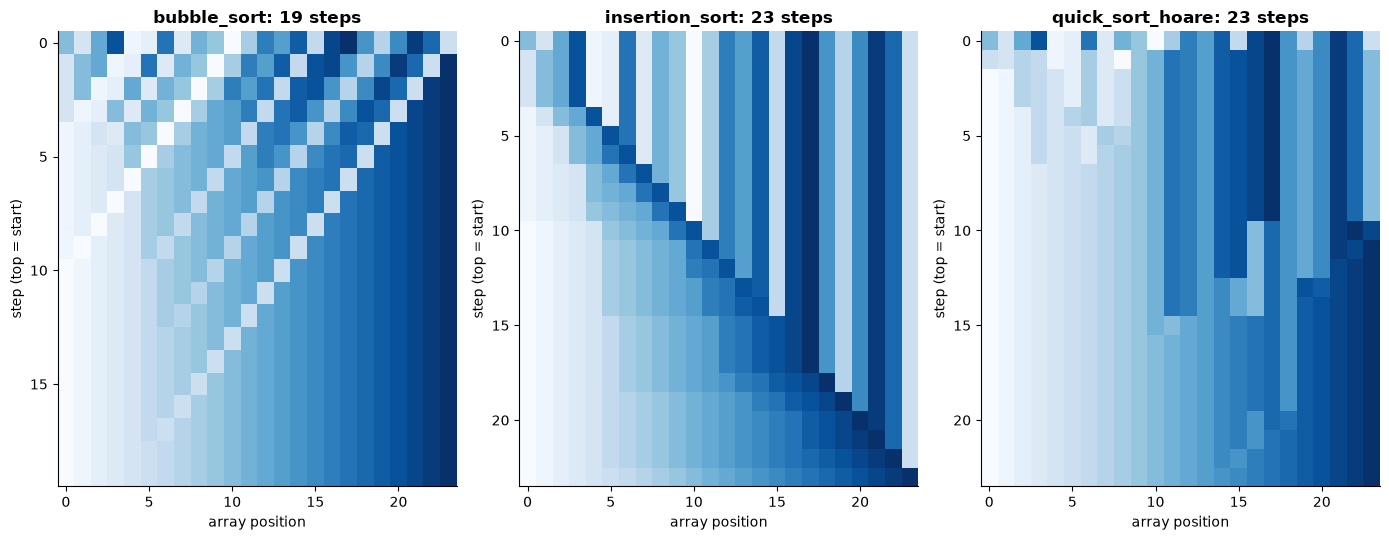

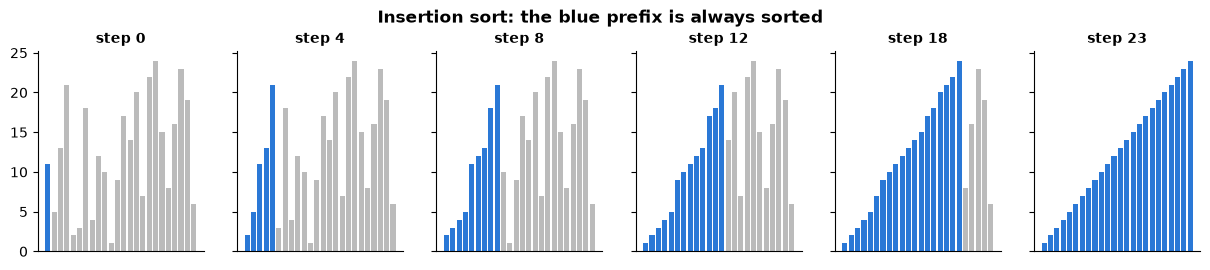

In [12]:
random.seed(7)
data = random.sample(range(1, 25), 24)                    # 24 distinct values in random order
fig, axes = plt.subplots(1, 3, figsize=(14, 5.5))
for ax, f in zip(axes, [bubble_sort, insertion_sort, quick_sort_hoare]):
    snaps = [data[:]]
    f(data, snap=snaps)
    ax.imshow(np.array(snaps), cmap="Blues", aspect="auto", interpolation="nearest")
    ax.set(title=f"{f.__name__}: {len(snaps) - 1} steps", xlabel="array position", ylabel="step (top = start)")
    ax.yaxis.get_major_locator().set_params(integer=True)
    ax.grid(False)
plt.tight_layout(); plt.show()

# Bar-chart frames of insertion sort
snaps = [data[:]]
insertion_sort(data, snap=snaps)
frames = [0, 4, 8, 12, 18, len(snaps) - 1]
fig, axes = plt.subplots(1, len(frames), figsize=(15, 2.6), sharey=True)
for ax, k in zip(axes, frames):
    colors = [PALETTE[0] if i <= k else "#bbbbbb" for i in range(len(data))]   # blue = sorted prefix
    ax.bar(range(len(data)), snaps[k], color=colors)
    ax.set_title(f"step {k}", fontsize=10); ax.set_xticks([]); ax.grid(False)
fig.suptitle("Insertion sort: the blue prefix is always sorted", fontweight="bold", y=1.04)
plt.show()
random.seed(42)

**What just happened?**
- **Bubble sort** (left): large values (dark) drift to the right one pass at a time; the right edge becomes sorted first.
- **Insertion sort** (middle): the left part becomes a smooth gradient that grows by one element per step, while the right part is untouched.
- **Quick sort with Hoare partitioning** (right): each partition step moves *many* elements a long way, so the array becomes coarsely ordered (light left, dark right) after very few steps, and later steps fix smaller regions.
- The bar frames show insertion sort's invariant: after step k, the first k + 1 bars (blue) are sorted.

---
## 9. Stability and in-place sorting

> 💡 **In plain English:** a stable sort keeps equal items in their original order; an in-place sort needs almost no extra memory.

A sort is **stable** if items with **equal keys keep their original relative order**. Why care? Sort a spreadsheet by city, then (stably) by country: rows stay ordered by city within each country. Multi-key sorting and LSD radix sort both rely on stability.

A sort is **in place** if it uses only O(1) (or, loosely, O(log n)) extra memory besides the input.

Let's *test* stability empirically: sort records by a key with many duplicates and check whether equal keys stay in input order.

In [13]:
from functools import total_ordering

@total_ordering
class Rec:
    """A record compared ONLY by key; tag remembers the original position."""
    def __init__(self, key, tag): self.key, self.tag = key, tag
    def __lt__(self, other): return self.key < other.key
    def __eq__(self, other): return self.key == other.key
    def __repr__(self): return f"{self.key}{self.tag}"

def is_stable_output(out):
    """Equal keys must appear with increasing tags."""
    return all(not (x.key == y.key and x.tag > y.tag) for x, y in zip(out, out[1:]))

algos = {f.__name__: f for f in comparison_sorts}
algos["counting_sort"] = lambda a: counting_sort(a, key=lambda r: r.key)
algos["bucket_sort (by key/10)"] = None                   # handled below
algos["sorted (Timsort)"] = sorted
rows = []
for name, f in algos.items():
    stable_every_time = True
    for trial in range(300):
        recs = [Rec(random.randint(0, 4), i) for i in range(random.randint(2, 25))]
        if f is None:                                     # bucket sort on keys mapped into [0, 1)
            n = len(recs); buckets = [[] for _ in range(n)]
            for r in recs: buckets[int(r.key / 5 * n)].append(r)
            out = [x for b in buckets for x in insertion_sort(b)]
        else:
            out = f(recs)
        assert [r.key for r in out] == sorted(r.key for r in recs)       # still correctly sorted
        stable_every_time &= is_stable_output(out)
    rows.append({"algorithm": name, "stable in 300 random trials?": "yes" if stable_every_time else "NO"})
example = [Rec(2, "a"), Rec(1, "b"), Rec(2, "c"), Rec(1, "d")]
print("input           :", example)
print("selection_sort  :", selection_sort(example), " ← 2a and 2c swapped order")
print("insertion_sort  :", insertion_sort(example))
pd.DataFrame(rows)

input           : [2a, 1b, 2c, 1d]
selection_sort  : [1b, 1d, 2c, 2a]  ← 2a and 2c swapped order
insertion_sort  : [1b, 1d, 2a, 2c]


,algorithm,stable in 300 random trials?
0,bubble_sort,yes
1,selection_sort,NO
2,insertion_sort,yes
3,merge_sort,yes
4,quick_sort_lomuto,NO
5,quick_sort_hoare,NO
6,quick_sort_random,NO
7,heap_sort,NO
8,counting_sort,yes
9,bucket_sort (by key/10),yes


**What just happened?** On the tiny example, selection sort's long-distance swap moved `2a` behind `2c`, so it is **not stable**; insertion sort kept `1b` before `1d` and `2a` before `2c`. The table repeats the experiment 300 times per algorithm: bubble, insertion, merge, counting, bucket and Timsort always preserved the order of equal keys, while selection, the quicksorts and heap sort broke it. (A test can only *prove* instability; stability itself follows from the code, e.g. merge takes ties from the left.)

> ⚠️ **Common mistake:** writing `if left[i] < right[j]: take left` in merge sort. With ties it takes from the *right* first, silently making merge sort unstable.

---
## 10. Comparison table and benchmark

> 💡 **In plain English:** one table compares all the sorts, and a race on random, sorted and reversed lists shows who wins when.

| Algorithm | Best | Average | Worst | Extra space | Stable? | In place? |
|---|---|---|---|---|---|---|
| Bubble (early exit) | Θ(n) | Θ(n²) | Θ(n²) | O(1) | yes | yes |
| Selection | Θ(n²) | Θ(n²) | Θ(n²) | O(1) | no | yes |
| Insertion | Θ(n) | Θ(n²) | Θ(n²) | O(1) | yes | yes |
| Merge | Θ(n log n) | Θ(n log n) | Θ(n log n) | Θ(n) | yes | no |
| Quick (good/random pivot) | Θ(n log n) | Θ(n log n) | Θ(n²) | O(log n) stack* | no | yes |
| Heap | Θ(n log n) | Θ(n log n) | Θ(n log n) | O(1) | no | yes |
| Counting (key range k) | Θ(n + k) | Θ(n + k) | Θ(n + k) | Θ(n + k) | yes | no |
| Radix (d digits, base b) | Θ(d(n + b)) | Θ(d(n + b)) | Θ(d(n + b)) | Θ(n + b) | yes | no |
| Bucket (n buckets) | Θ(n) | Θ(n) for uniform data | Θ(n²) | Θ(n) | yes** | no |
| Timsort (`sorted`) | Θ(n) | Θ(n log n) | Θ(n log n) | O(n) | yes | no |

\* when recursing on the smaller part first; naive recursion can need O(n) stack. \*\* if the per-bucket sort is stable.

Now the benchmark: n = 2000 integers in [0, 10000) arranged **randomly**, **already sorted** and **reversed** (bucket sort gets the same values divided by 10000).

,random,sorted,reversed
bubble,873.59,0.38,875.07
selection,575.89,477.33,262.15
insertion,427.33,0.73,582.90
merge,11.89,8.68,8.90
"quick (Lomuto, last pivot)",7.10,527.23,403.50
"quick (Hoare, middle pivot)",6.75,4.26,4.70
quick (random pivot),9.33,8.25,8.15
heap,11.65,11.66,9.38
counting,3.31,3.18,3.38
radix (base 10),5.70,5.58,6.01


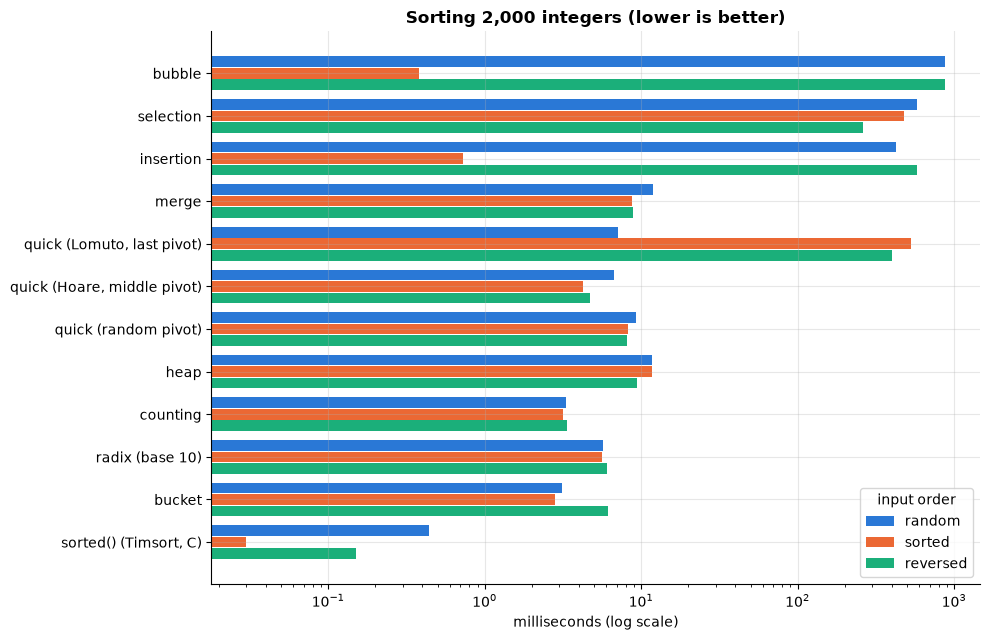

In [14]:
N = 2000
base = [random.randrange(10_000) for _ in range(N)]
inputs = {"random": base, "sorted": sorted(base), "reversed": sorted(base, reverse=True)}
bench_algos = {
    "bubble": bubble_sort, "selection": selection_sort, "insertion": insertion_sort,
    "merge": merge_sort, "quick (Lomuto, last pivot)": quick_sort_lomuto,
    "quick (Hoare, middle pivot)": quick_sort_hoare, "quick (random pivot)": quick_sort_random,
    "heap": heap_sort, "counting": counting_sort, "radix (base 10)": radix_sort,
    "bucket": lambda a: bucket_sort([x / 10_000 for x in a]), "sorted() (Timsort, C)": sorted,
}
results = {}
for name, f in bench_algos.items():
    results[name] = {}
    for kind, data in inputs.items():
        results[name][kind] = min(timeit.repeat(lambda: f(data), number=1, repeat=3)) * 1000   # ms (best of 3)
bench = pd.DataFrame(results).T.round(2)
display(bench)

fig, ax = plt.subplots(figsize=(10, 6.5))
y = np.arange(len(bench))
for k, (kind, col) in enumerate(zip(inputs, PALETTE)):
    ax.barh(y + (k - 1) * 0.27, bench[kind], height=0.25, color=col, label=kind)
ax.set_yticks(y, bench.index); ax.invert_yaxis(); ax.set_xscale("log")
ax.set(title=f"Sorting {N:,} integers (lower is better)", xlabel="milliseconds (log scale)")
ax.legend(title="input order"); plt.tight_layout(); plt.show()

**What just happened?** (Exact times depend on your machine; the *patterns* are what matter.)
- **Quadratic sorts are slow on random data**, but **bubble (with early exit) and insertion sort are nearly instant on sorted input** (Θ(n): one pass with no swaps/shifts). On reversed input insertion sort hits its worst case.
- **Quick sort with a last-element pivot collapses on sorted and reversed input** (every partition is maximally unbalanced → Θ(n²)), while the **middle-pivot (Hoare)** and **random-pivot** versions stay fast on every input.
- **Merge and heap sort** have no bad input order (Θ(n log n) always); any differences between their three bars are small and mostly measurement noise.
- **Counting, radix and bucket sort** are in the same league as the best comparison sorts (often the fastest pure-Python sorts on a quiet machine) because they never compare elements; this works because the key range (10,000) is small relative to n.
- **`sorted()`** wins by a wide margin: it is implemented in C, and on sorted or reversed input Timsort finishes in a single linear pass (section 12).

Let's also check the **growth** with n on random data (log-log, as in notebook 01).

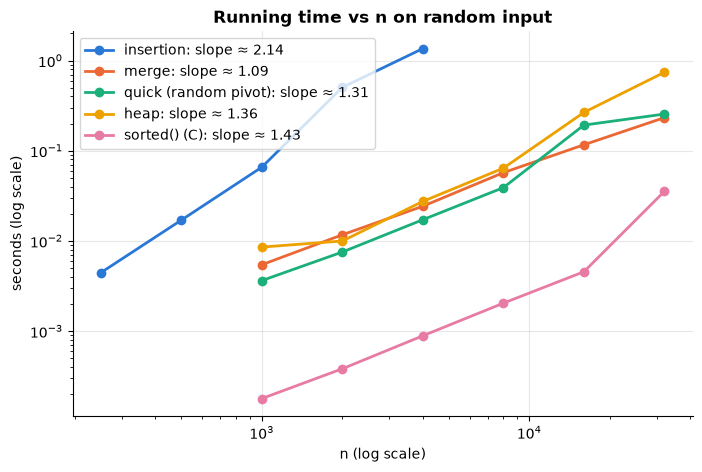

In [15]:
growth_algos = {"insertion": (insertion_sort, [250, 500, 1000, 2000, 4000]),
                "merge": (merge_sort, [1000, 2000, 4000, 8000, 16000, 32000]),
                "quick (random pivot)": (quick_sort_random, [1000, 2000, 4000, 8000, 16000, 32000]),
                "heap": (heap_sort, [1000, 2000, 4000, 8000, 16000, 32000]),
                "sorted() (C)": (sorted, [1000, 2000, 4000, 8000, 16000, 32000])}
fig, ax = plt.subplots(figsize=(8, 5))
for (name, (f, sizes)), col in zip(growth_algos.items(), PALETTE):
    ts = []
    for n in sizes:
        data = [random.random() for _ in range(n)]
        ts.append(min(timeit.repeat(lambda: f(data), number=1, repeat=3)))   # min of 3 runs reduces noise
    slope = np.polyfit(np.log(sizes), np.log(ts), 1)[0]
    ax.loglog(sizes, ts, "o-", color=col, label=f"{name}: slope ≈ {slope:.2f}")
ax.set(title="Running time vs n on random input", xlabel="n (log scale)", ylabel="seconds (log scale)")
ax.legend(); plt.show()

**What just happened?** Insertion sort's line has slope ≈ 2 (quadratic), while merge, quick and heap sort have slopes a little above 1 (n log n, plus cache effects; single points can wobble if the computer is busy). `sorted()` is a parallel line far below: same growth rate, a much smaller constant factor because it is compiled C. **Growth rate decides who wins for large n; constant factors decide among algorithms with the same growth rate.**

---
## 11. The Ω(n log n) lower bound for comparison sorts

> 💡 **In plain English:** any sort that only compares pairs must make about n log n comparisons, so merge sort can't be beaten by much.

**Claim.** Any sorting algorithm that learns about the input *only by comparing pairs of elements* needs **Ω(n log n)** comparisons in the worst case.

**Proof idea: the decision tree.** Model the algorithm as a binary tree: each internal node is a comparison "a[i] < a[j]?", each leaf is one final ordering. For n = 3:
```
                    a<b?
               yes /     \ no
               b<c?        a<c?
             /     \      /     \
         a,b,c     a<c?  b,a,c   b<c?
                  /   \          /   \
              a,c,b  c,a,b    b,c,a  c,b,a
```
1. The algorithm must be able to output **every one of the n! permutations**, so the tree has **≥ n! leaves**.
2. A binary tree of height h has at most **2ʰ** leaves, so 2ʰ ≥ n!, i.e. **h ≥ log₂(n!)**.
3. By Stirling's approximation, log₂(n!) = n log₂ n − n log₂ e + O(log n) = **Θ(n log n)**.

The height h is the worst-case number of comparisons, so every comparison sort needs Ω(n log n) comparisons. Merge sort and heap sort are therefore **asymptotically optimal**. Counting, radix and bucket sort escape the bound because they look at the *values* (as array indices / digits), not just comparisons.

For n = 3: 3! = 6 leaves → h ≥ ⌈log₂ 6⌉ = 3 comparisons, exactly the height of the tree above.

In [16]:
class Counted:
    """Wraps a value and counts every '<' comparison made on it."""
    __slots__ = ("v",)
    comparisons = 0
    def __init__(self, v): self.v = v
    def __lt__(self, other):
        Counted.comparisons += 1
        return self.v < other.v

def count_comparisons(sort_fn, values):
    Counted.comparisons = 0
    out = sort_fn([Counted(v) for v in values])
    assert [c.v for c in out] == sorted(values)
    return Counted.comparisons

from itertools import permutations

rows = []
for n in [3, 6, 8, 100, 1000, 10_000]:
    if n <= 8:                                    # exhaustive: every one of the n! inputs → the TRUE worst case
        inputs_ = [list(p) for p in permutations(range(n))]
        how = f"all {len(inputs_):,} permutations"
    else:                                         # too many permutations: sample 5 random inputs
        inputs_ = [random.sample(range(10 * n), n) for _ in range(5)]
        how = "5 random inputs"
    bound = math.ceil(math.lgamma(n + 1) / math.log(2))          # ceil(log2(n!))
    m = [count_comparisons(merge_sort, v) for v in inputs_]
    t = [count_comparisons(sorted, v) for v in inputs_]
    rows.append({"n": n, "inputs tried": how, "⌈log₂ n!⌉ bound": bound, "n log₂ n": round(n * math.log2(n)),
                 "merge: worst": max(m), "merge: mean": round(np.mean(m), 1),
                 "sorted(): worst": max(t), "sorted(): mean": round(np.mean(t), 1),
                 "sorted(): best": min(t)})
lb = pd.DataFrame(rows)
display(lb)
exhaustive = lb[lb.n <= 8]
assert (exhaustive["merge: worst"] >= exhaustive["⌈log₂ n!⌉ bound"]).all()      # the theorem (worst case)
assert (exhaustive["sorted(): worst"] >= exhaustive["⌈log₂ n!⌉ bound"]).all()
assert (lb["merge: mean"] >= lb["⌈log₂ n!⌉ bound"] - 1).all() and (lb["sorted(): mean"] >= lb["⌈log₂ n!⌉ bound"] - 1).all()

,n,inputs tried,⌈log₂ n!⌉ bound,n log₂ n,merge: worst,merge: mean,sorted(): worst,sorted(): mean,sorted(): best
0,3,all 6 permutations,3,5,3,2.7,4,3.2,2
1,6,all 720 permutations,10,16,11,9.8,12,10.5,5
2,8,"all 40,320 permutations",16,24,17,15.7,18,16.3,7
3,100,5 random inputs,525,664,545,537.8,540,533.8,527
4,1000,5 random inputs,8530,9966,8738,8708.4,8642,8626.2,8611
5,10000,5 random inputs,118459,132877,120497,120442.0,119878,119812.2,119763


**What just happened?** We counted every comparison made by our merge sort and by Python's `sorted()`. For n = 3, 6 and 8 we tried **every** possible input order, so the "worst" columns are the true worst cases, and they are always ≥ ⌈log₂ n!⌉, as the theorem requires. Note the "sorted(): best" column: on a *lucky* input (e.g. already sorted) Timsort needs only n − 1 comparisons, below the bound. That does not contradict the theorem, which is about the **worst case**. (A similar counting argument shows the *average* over all n! inputs is at least log₂ n!, without the ceiling; that is why the mean for n = 3 can be 2.7 ≥ log₂ 6 ≈ 2.58.) For large n, both algorithms stay within a few percent of the bound on random inputs: for n = 10,000 the bound is about 118,000 comparisons. (Note ⌈log₂ n!⌉ is noticeably *below* n log₂ n because of the −n log₂ e term in Stirling's formula.)

---
## 12. Timsort: what Python's `sorted` really does

> 💡 **In plain English:** Python's sorted() spots already-ordered stretches in your data and merges them, which makes it very fast on real data.

**Timsort** was designed by Tim Peters for Python in 2002 and is also used by Java (for objects), Android, V8/JavaScript and Swift. It is a **hybrid, stable, adaptive** merge sort:
1. Scan the input for **natural runs**: maximal stretches that are already non-decreasing, or strictly decreasing (which are reversed in place).
2. Short runs are extended to a minimum length (**minrun**, between 32 and 64) using **binary insertion sort**, which is fast on small arrays.
3. Runs are pushed on a stack and **merged** according to rules that keep merges balanced. Since Python 3.11, CPython chooses merges with the **powersort** policy (Munro & Wild), which has provably near-optimal merge costs.
4. When one run keeps "winning" during a merge, Timsort switches to **galloping mode** (exponential + binary search) to copy long blocks at once.

Consequences: Θ(n) comparisons on sorted or reversed input, Θ(n log n) worst case, and very few comparisons on real-world data that is often partially ordered (appended logs, nearly sorted timestamps, concatenated sorted files).

In [17]:
n = 10_000
rand = random.sample(range(n), n)
nearly = list(range(n))
for _ in range(20):                                       # 20 random swaps
    i, j = random.randrange(n), random.randrange(n); nearly[i], nearly[j] = nearly[j], nearly[i]
four_runs = sorted(rand[:2500]) + sorted(rand[2500:5000]) + sorted(rand[5000:7500]) + sorted(rand[7500:])
cases = {"random": rand, "already sorted": list(range(n)), "reversed": list(range(n, 0, -1)),
         "nearly sorted (20 swaps)": nearly, "4 sorted runs concatenated": four_runs}
rows = [{"input": k, "sorted() comparisons": count_comparisons(sorted, v),
         "merge sort comparisons": count_comparisons(merge_sort, v)} for k, v in cases.items()]
tim = pd.DataFrame(rows)
tim["sorted() / (n log₂ n)"] = (tim["sorted() comparisons"] / (n * math.log2(n))).round(3)
display(tim)
assert tim.loc[1, "sorted() comparisons"] == n - 1 and tim.loc[2, "sorted() comparisons"] == n - 1

,input,sorted() comparisons,merge sort comparisons,sorted() / (n log₂ n)
0,random,119823,120468,0.902
1,already sorted,9999,64608,0.075
2,reversed,9999,69008,0.075
3,nearly sorted (20 swaps),12153,83582,0.091
4,4 sorted runs concatenated,29999,74602,0.226


**What just happened?** On random input `sorted()` and our merge sort need a similar number of comparisons (about n log₂ n). But Timsort needs exactly **n − 1 = 9,999 comparisons on already sorted *and* on reversed input** (one run, detected in a single scan), and a small fraction of n log₂ n on nearly sorted data or a few concatenated sorted runs, while plain merge sort does not adapt to existing order. That adaptivity, plus being written in C, is why `sorted()`/`list.sort()` should be your default.

> 🎓 **Exam / interview tip:** "Which sort does Python use?" → Timsort: hybrid of merge sort and binary insertion sort, stable, O(n log n) worst case, O(n) best case on presorted data, O(n) extra memory.

---
## 13. Quickselect and merging intervals

> 💡 **In plain English:** find the k-th smallest item without a full sort, and merge overlapping time ranges.

### Quickselect: the k-th smallest element
To find the median or the k-th smallest element you don't need to sort everything. **Quickselect** (Hoare, 1961) partitions like quicksort but then **recurses into only the side that contains position k**.
- Expected time with a random pivot: n + n/2 + n/4 + … ≈ 2n → **Θ(n)**. Worst case Θ(n²).
- The **median-of-medians** pivot rule guarantees Θ(n) worst case (CLRS 9.3), but is slower in practice. NumPy's `np.partition` uses **introselect** (quickselect with a fallback).

We use a **3-way partition** (Dutch national flag from notebook 02) so that many duplicate values don't slow it down.

### Merging intervals
Given intervals like `[1, 3], [2, 6], [8, 10], [15, 18]`, merge all overlapping ones: `[1, 6], [8, 10], [15, 18]`. **Sort by start**, then sweep: if the next interval starts at or before the current end, extend the end; otherwise start a new interval. **O(n log n)** for the sort + O(n) sweep. (Used for calendar free-slot finding and merging overlapping text spans/entities.)

In [18]:
def quickselect(a, k):
    """Return the k-th smallest element (k = 0 is the minimum). Expected O(n)."""
    a = list(a)
    lo, hi = 0, len(a) - 1
    while True:
        if lo == hi:
            return a[lo]
        pivot = a[random.randint(lo, hi)]
        lt, i, gt = lo, lo, hi                    # 3-way partition: < pivot | == pivot | > pivot
        while i <= gt:
            if a[i] < pivot:   a[lt], a[i] = a[i], a[lt]; lt += 1; i += 1
            elif a[i] > pivot: a[i], a[gt] = a[gt], a[i]; gt -= 1
            else:              i += 1
        if k < lt:   hi = lt - 1                  # answer is in the "<" part
        elif k > gt: lo = gt + 1                  # answer is in the ">" part
        else:        return pivot                 # k falls in the "==" block

def merge_intervals(intervals):
    out = []
    for s, e in sorted(intervals):                # sort by start
        if out and s <= out[-1][1]:               # overlaps (or touches) the last merged interval
            out[-1][1] = max(out[-1][1], e)
        else:
            out.append([s, e])
    return out

def merge_intervals_brute(intervals):
    """Reference: mark covered points on a doubled integer grid (so [1,2],[3,4] stay separate)."""
    covered = set()
    for s, e in intervals:
        covered.update(range(2 * s, 2 * e + 1))
    out, pts = [], sorted(covered)
    for p in pts:
        if out and p == out[-1][1] + 1:
            out[-1][1] = p
        else:
            out.append([p, p])
    return [[s // 2, e // 2] for s, e in out]

print("quickselect median of [7, 2, 9, 4, 4, 1, 8] =", quickselect([7, 2, 9, 4, 4, 1, 8], 3))
print("merge_intervals:", merge_intervals([[1, 3], [2, 6], [8, 10], [15, 18]]))

for _ in range(3000):
    a = [random.randint(0, 10) for _ in range(random.randint(1, 20))]
    k = random.randrange(len(a))
    assert quickselect(a, k) == sorted(a)[k] == np.partition(np.array(a), k)[k]
    iv = [(lambda s: [s, s + random.randint(0, 5)])(random.randint(0, 25)) for _ in range(random.randint(0, 8))]
    assert merge_intervals(iv) == merge_intervals_brute(iv)
print("3000 random tests: quickselect == sorted(a)[k] == np.partition; merge_intervals == brute force")

big = [random.random() for _ in range(300_000)]
t_sel = min(timeit.repeat(lambda: quickselect(big, len(big) // 2), number=1, repeat=2))
t_sort = min(timeit.repeat(lambda: sorted(big)[len(big) // 2], number=1, repeat=2))
t_np = min(timeit.repeat(lambda: np.partition(np.array(big), len(big) // 2), number=1, repeat=2))
print(f"median of 300,000 floats: pure-Python quickselect {t_sel * 1000:.0f} ms | sorted() {t_sort * 1000:.0f} ms | np.partition {t_np * 1000:.0f} ms (incl. list→array)")

quickselect median of [7, 2, 9, 4, 4, 1, 8] = 4
merge_intervals: [[1, 6], [8, 10], [15, 18]]


3000 random tests: quickselect == sorted(a)[k] == np.partition; merge_intervals == brute force


median of 300,000 floats: pure-Python quickselect 1642 ms | sorted() 524 ms | np.partition 96 ms (incl. list→array)


**What just happened?** Quickselect returns 4 as the median (k = 3) of `[7, 2, 9, 4, 4, 1, 8]`, and the intervals merge into `[[1, 6], [8, 10], [15, 18]]`. Both agree with brute-force references (and with `np.partition`) on 3000 random tests. In the timing, our pure-Python Θ(n) quickselect is still *slower* than the C-implemented Θ(n log n) `sorted()` at this size: the constant-factor gap between interpreted Python and C (often 50× or more) outweighs the log₂ n ≈ 18 factor. NumPy's introselect has both the better algorithm *and* the C implementation, so it is clearly fastest. Lesson: asymptotics tell you how things scale; constants still matter at a fixed n.

---
## 14. 🔗 How this connects to modern AI

> 💡 **In plain English:** sorting, binary search and top-k selection are inside LLM sampling, retrieval and evaluation.

- **Sampling the next token in an LLM** is binary search on a prefix-sum array: compute the cumulative probabilities, draw u ~ Uniform(0, 1) and find the first cumulative value > u (`bisect`). **Top-k** sampling needs the k largest probabilities (a selection problem: `np.argpartition`, `torch.topk`), and **top-p (nucleus)** sampling sorts probabilities in decreasing order and keeps the smallest prefix whose sum ≥ p. A small demo follows. See [language models and generation](../../07_NLP/05_language_models_and_generation.ipynb).
- **Retrieval for RAG and recommendation** returns the top-k most similar items: a partial sort / heap / quickselect problem, not a full sort. See [RAG fundamentals](../../08_LLM/02_rag/01_rag_fundamentals.ipynb) and [recommendation systems](../../03_Machine_Learning/09_recommendation_systems/01_recommendation_systems.ipynb).
- **Evaluation metrics** like ROC-AUC are computed by sorting scores (O(n log n)), and **threshold tuning** is a binary search over a monotone metric. See [evaluation metrics](../../03_Machine_Learning/10_evaluation_metrics_comprehensive.ipynb).
- **Decision trees and gradient boosting** sort (or histogram-bucket, like counting sort) each feature to find the best split; LightGBM and XGBoost's `hist` method use **bucketing** precisely to avoid repeated O(n log n) sorts.
- **Binary search on the answer** appears when tuning a learning-rate or batch-size limit ("largest batch that fits in GPU memory").

In [19]:
# Demo: sampling tokens from an LLM-style next-token distribution with prefix sums + binary search
vocab = ["the", "a", "cat", "dog", "sat", "ran"]
probs = np.array([0.35, 0.25, 0.15, 0.12, 0.08, 0.05])
cdf = np.cumsum(probs)                                       # prefix sums: [0.35, 0.60, 0.75, ...]

def sample_token(u):
    return bisect.bisect_right(cdf.tolist(), u)              # first index with cdf > u

rng = random.Random(0)
draws = Counter(vocab[sample_token(rng.random())] for _ in range(100_000))
freq = pd.DataFrame({"true p": probs, "sampled freq": [draws[w] / 100_000 for w in vocab]}, index=vocab)

def top_p_filter(p, top_p):
    """Nucleus sampling: keep the most likely tokens whose total probability first reaches top_p."""
    order = np.argsort(-p)                                   # sort descending
    keep = order[: np.searchsorted(np.cumsum(p[order]), top_p) + 1]
    q = np.zeros_like(p); q[keep] = p[keep]
    return q / q.sum()
freq["top-p 0.7 renormalised"] = top_p_filter(probs, 0.7).round(3)
display(freq.round(3))
assert np.allclose(freq["sampled freq"], probs, atol=0.01)

,true p,sampled freq,top-p 0.7 renormalised
the,0.35,0.352,0.467
a,0.25,0.249,0.333
cat,0.15,0.148,0.200
dog,0.12,0.120,0.000
sat,0.08,0.081,0.000
ran,0.05,0.050,0.000


**What just happened?** Sampling 100,000 tokens with `bisect` on the cumulative distribution reproduces the true probabilities to within about ±0.01. With top-p = 0.7 only "the", "a" and "cat" survive (0.35 + 0.25 + 0.15 = 0.75 ≥ 0.7) and their probabilities are renormalised to sum to 1: a sort, a prefix sum and a binary search, the three tools of this notebook.

---
## Recap
- **Linear search** is O(n) and works on anything; **binary search** is O(log n) on sorted data. Know the closed vs. half-open conventions, **lower_bound / upper_bound** (`bisect_left` / `bisect_right`), rotated arrays, and **binary search on a monotone answer**.
- **Elementary sorts** (bubble, selection, insertion) are Θ(n²); insertion sort is excellent for small or nearly sorted data.
- **Merge sort**: Θ(n log n) always, stable, Θ(n) extra space. **Quick sort**: Θ(n log n) expected with a good/random pivot, Θ(n²) worst case, in place, not stable. **Heap sort**: Θ(n log n) always, in place, not stable.
- **Counting / radix / bucket** sorts beat n log n by exploiting the key structure (small integer range, digits, uniform distribution).
- **Stability** keeps equal keys in input order; it matters for multi-key sorts and radix sort.
- Comparison sorts need **Ω(n log n)** comparisons (decision tree with n! leaves).
- **Timsort** (`sorted`) is a stable, adaptive merge/insertion hybrid: O(n) on presorted data. Use it by default.
- **Quickselect** finds the k-th smallest in expected O(n); **merging intervals** = sort by start + sweep.

## Practice problems

**1. (Easy, conceptual)** Which sort would you choose, and why? (a) 1 million records that must keep their previous order for equal keys; (b) an array that is already sorted except for 3 elements; (c) 10 million ages (integers 0–120); (d) an embedded device with almost no spare memory that needs a guaranteed worst case.

<details><summary>Show solution</summary>

(a) A **stable** O(n log n) sort: merge sort / Timsort (`sorted`).
(b) **Insertion sort** (or Timsort): nearly sorted input → close to O(n).
(c) **Counting sort**: key range k = 121 ≪ n → Θ(n + k).
(d) **Heap sort**: Θ(n log n) worst case with O(1) extra space.

</details>

**2. (Easy, conceptual)** How many comparisons does binary search need, at most, on 1,000,000 sorted items? On 2³⁰ items? Why must the array be sorted?

<details><summary>Show solution</summary>

At most ⌊log₂ n⌋ + 1: **20** for 10⁶ (2¹⁹ = 524,288 ≤ 10⁶ < 2²⁰), and **31** for 2³⁰. Sortedness is what lets one comparison with the middle element rule out a whole half: without order, the target could be anywhere.

</details>

**3. (Easy, coding)** *First bad version*: versions 1…n, and once a version is bad all later ones are bad. Given `is_bad(v)`, find the first bad version with O(log n) calls.

<details><summary>Show solution</summary>

Binary search on a monotone predicate (F F F T T T).
```python
def first_bad_version(n, is_bad):
    """Versions 1..n; once a version is bad, all later ones are bad. Find the first bad one with O(log n) calls."""
    lo, hi = 1, n                       # the answer is in [lo, hi]
    while lo < hi:
        mid = (lo + hi) // 2
        if is_bad(mid):
            hi = mid                    # mid might be the first bad one
        else:
            lo = mid + 1                # first bad is after mid
    return lo
```
Tested with n up to 10⁶ and at most 21 calls.

</details>

**4. (Medium, coding)** Find the minimum of a rotated sorted array of distinct values in O(log n).

<details><summary>Show solution</summary>

Compare `a[mid]` with `a[hi]`: if it is larger, the rotation point is to the right.
```python
def find_min_rotated(a):
    """Minimum of a rotated sorted array of distinct values in O(log n)."""
    lo, hi = 0, len(a) - 1
    while lo < hi:
        mid = (lo + hi) // 2
        if a[mid] > a[hi]:              # the drop (minimum) is to the right of mid
            lo = mid + 1
        else:                           # a[mid..hi] is sorted: the minimum is at mid or to its left
            hi = mid
    return a[lo]
```

</details>

**5. (Medium, coding)** Sort a list of integers by decreasing frequency; ties broken by increasing value. `[4, 6, 2, 6, 4, 4, 2, 9]` → `[4, 4, 4, 2, 2, 6, 6, 9]`.

<details><summary>Show solution</summary>

Count with a hash map, then sort with a composite key (Timsort, O(n log n)).
```python
def sort_by_frequency(a):
    """Sort by decreasing frequency; ties by increasing value. Uses two stable sorts (or one key)."""
    from collections import Counter
    freq = Counter(a)
    return sorted(a, key=lambda x: (-freq[x], x))
```

</details>

**6. (Medium/Hard, coding)** Count **inversions** (pairs i < j with a[i] > a[j]) in O(n log n). (The inversion count measures how far a list is from sorted; insertion sort performs exactly that many shifts.)

<details><summary>Show solution</summary>

Piggyback on merge sort: when an element from the right half is placed before the remaining left elements, it forms an inversion with each of them.
```python
def count_inversions(a):
    """Number of pairs i < j with a[i] > a[j], via merge sort in O(n log n)."""
    def sort_count(arr):
        if len(arr) <= 1:
            return arr, 0
        mid = len(arr) // 2
        left, x = sort_count(arr[:mid])
        right, y = sort_count(arr[mid:])
        merged, i, j, inv = [], 0, 0, x + y
        while i < len(left) and j < len(right):
            if right[j] < left[i]:
                merged.append(right[j]); j += 1
                inv += len(left) - i        # right[j] is smaller than ALL remaining left items
            else:
                merged.append(left[i]); i += 1
        merged += left[i:] + right[j:]
        return merged, inv
    return sort_count(list(a))[1]
```
Tested against the O(n²) definition on 2000 random arrays.

</details>

**7. (Medium, coding)** Return the k points closest to the origin from a list of (x, y) points, faster than sorting all of them when k ≪ n.

<details><summary>Show solution</summary>

Keep a max-heap of the k best so far (Python's `heapq` is a min-heap, so store negative distances): O(n log k) time, O(k) space. Quickselect would give expected O(n).
```python
import heapq

def k_closest(points, k):
    """k points closest to the origin. Max-heap of size k (store negative distances): O(n log k)."""
    heap = []
    for (x, y) in points:
        d = x * x + y * y
        if len(heap) < k:
            heapq.heappush(heap, (-d, x, y))
        elif -heap[0][0] > d:                   # closer than the farthest kept point
            heapq.heapreplace(heap, (-d, x, y))
    return sorted((x, y) for _, x, y in heap)
```

</details>

**8. (Hard, conceptual)** Why does LSD radix sort *require* the per-digit sort to be stable? Give a 2-element counterexample with an unstable digit sort.

<details><summary>Show solution</summary>

After the pass on the 1s digit, numbers are correctly ordered by their last digit. The pass on the 10s digit must keep that order whenever two numbers have the *same* 10s digit, and "keep the order of equal keys" is exactly stability.
Counterexample: `[12, 11]`. Pass 1 (1s digit, keys 2 and 1) gives `[11, 12]`. Pass 2 (10s digit) sees two equal keys (1 and 1); an unstable sort is allowed to swap them and output `[12, 11]`, undoing pass 1 and giving a wrong final result.

</details>

## Further reading
- Cormen et al., *Introduction to Algorithms* (CLRS, 4th ed.): ch. 2 (insertion sort, merge sort), ch. 6 (heapsort), ch. 7 (quicksort), ch. 8 (lower bound, counting/radix/bucket sort), ch. 9 (selection in linear time).
- Sedgewick & Wayne, *Algorithms* (4th ed.), ch. 2 (sorting) and 3.1 (binary search); free booksite: https://algs4.cs.princeton.edu/
- Knuth, *The Art of Computer Programming*, vol. 3 (Sorting and Searching).
- Tim Peters, `listsort.txt` (the design notes of Timsort, in the CPython source tree): https://github.com/python/cpython/blob/main/Objects/listsort.txt
- GeeksforGeeks: [Searching algorithms](https://www.geeksforgeeks.org/searching-algorithms/) and [Sorting algorithms](https://www.geeksforgeeks.org/sorting-algorithms/).

## Next notebook
➡️ [04 · Hashing](04_hashing.ipynb): hash functions, collision resolution (chaining and open addressing, built from scratch), how Python's dict works, Bloom filters and MinHash.